In [4]:
!pip install -q xgboost shap

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings("ignore")

In [5]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(df.shape)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
df = df.dropna().drop(columns=["customerID"])
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
print("Churn rate:", round(df["Churn"].mean()*100, 1), "%")

(7043, 21)
Missing values:
 TotalCharges    11
dtype: int64
Churn rate: 26.6 %


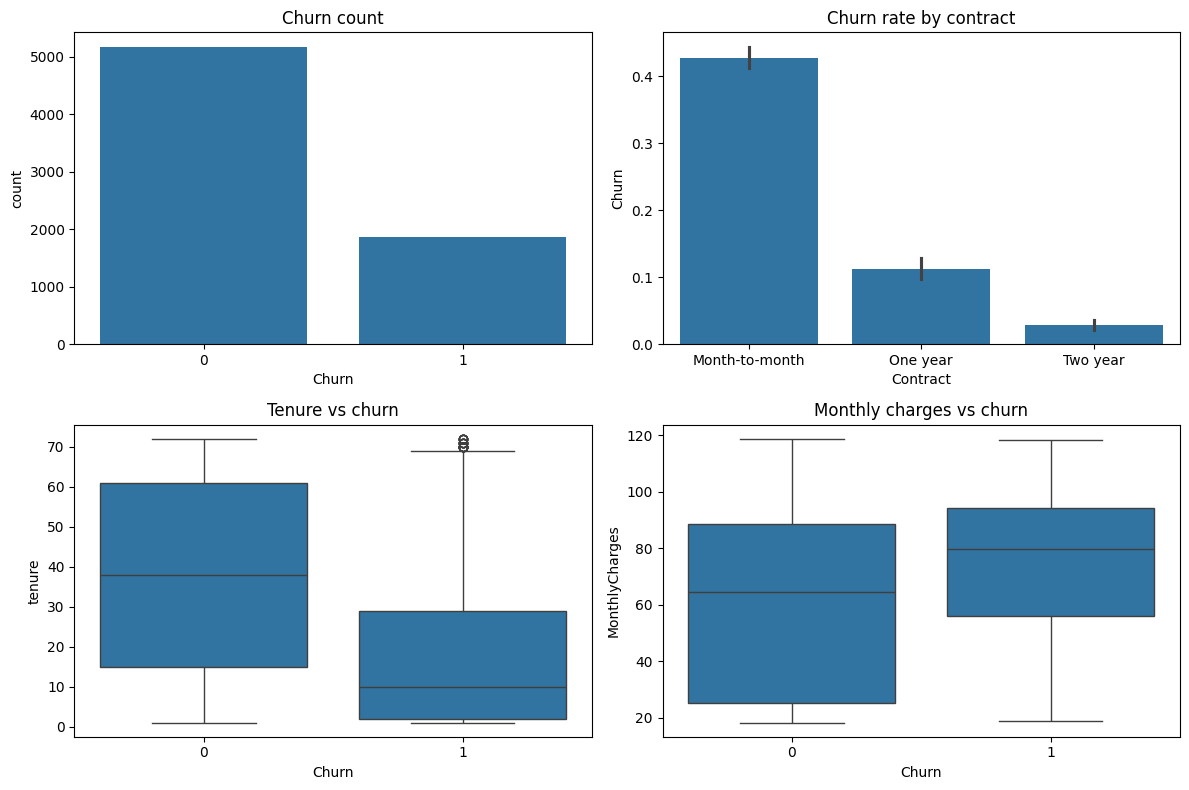

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
sns.countplot(data=df, x="Churn", ax=ax[0,0]).set_title("Churn count")
sns.barplot(data=df, x="Contract", y="Churn", ax=ax[0,1]).set_title("Churn rate by contract")
sns.boxplot(data=df, x="Churn", y="tenure", ax=ax[1,0]).set_title("Tenure vs churn")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=ax[1,1]).set_title("Monthly charges vs churn")
plt.tight_layout(); plt.show()

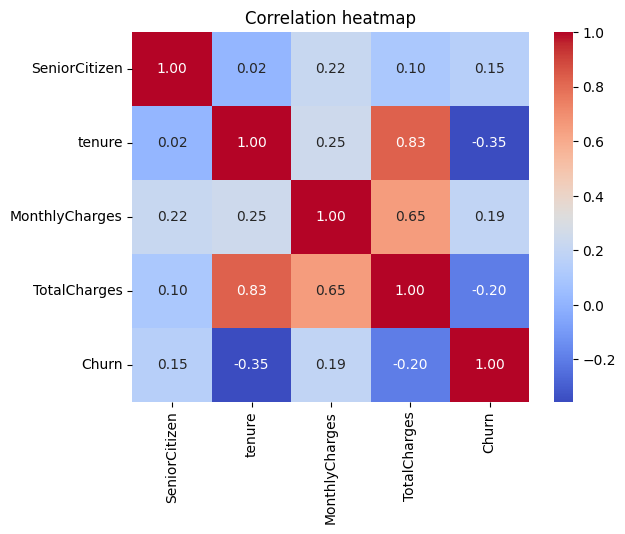

In [7]:
num = df.select_dtypes("number")
sns.heatmap(num.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap"); plt.show()

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from xgboost import XGBClassifier

X = pd.get_dummies(df.drop(columns="Churn"), drop_first=True)
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

ratio = (y_train == 0).sum() / (y_train == 1).sum()
print(X_train.shape, X_test.shape)

(5625, 30) (1407, 30)


In [9]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
        class_weight="balanced", random_state=42),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
        scale_pos_weight=ratio, eval_metric="logloss", random_state=42),
}

rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, proba)})

results = pd.DataFrame(rows).set_index("Model").round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.726,0.491,0.797,0.608,0.835
Random Forest,0.768,0.546,0.746,0.631,0.836
XGBoost,0.729,0.493,0.783,0.605,0.834


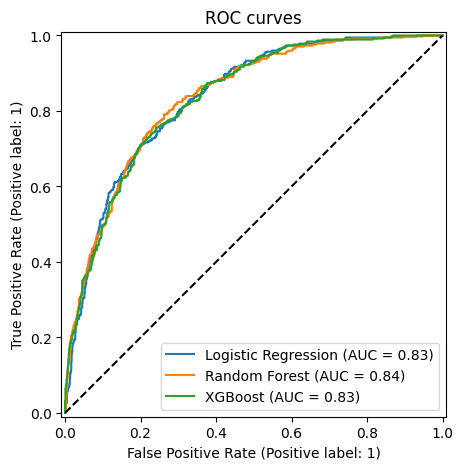

In [10]:
from sklearn.metrics import RocCurveDisplay
fig, ax = plt.subplots(figsize=(6, 5))
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--")
plt.title("ROC curves"); plt.show()

In [11]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators": [200, 300, 500],
    "max_depth": [6, 8, 10, 12, None],
    "min_samples_leaf": [3, 5, 10, 20],
    "max_features": ["sqrt", 0.3, 0.5],
}
search = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42),
    param_dist, n_iter=20, scoring="roc_auc", cv=5, random_state=42, n_jobs=-1)
search.fit(X_train, y_train)

best_rf = search.best_estimator_
print("Best params:", search.best_params_)
print("CV AUC:", round(search.best_score_, 3))
print("Test AUC:", round(roc_auc_score(y_test, best_rf.predict_proba(X_test)[:, 1]), 3))

Best params: {'n_estimators': 300, 'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 12}
CV AUC: 0.848
Test AUC: 0.841


In [12]:
proba = best_rf.predict_proba(X_test)[:, 1]
rows = []
for t in [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6]:
    p = (proba >= t).astype(int)
    rows.append({"Threshold": t,
                 "Precision": precision_score(y_test, p),
                 "Recall": recall_score(y_test, p),
                 "F1": f1_score(y_test, p)})
pd.DataFrame(rows).round(3)

,Threshold,Precision,Recall,F1
0,0.30,0.422,0.909,0.577
1,0.35,0.441,0.896,0.591
2,0.40,0.456,0.864,0.597
3,0.45,0.487,0.840,0.616
4,0.50,0.525,0.791,0.631
5,0.55,0.560,0.735,0.636
6,0.60,0.579,0.663,0.618


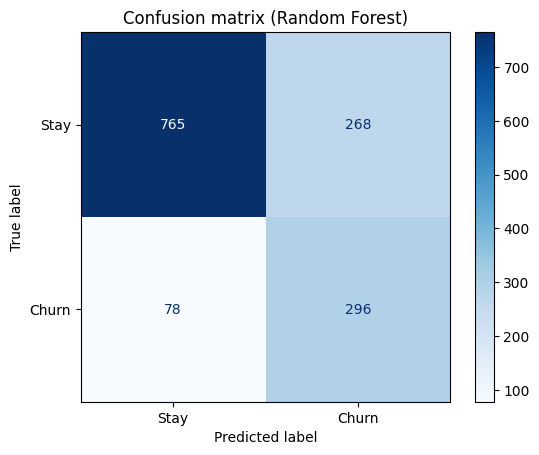

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, (proba >= 0.5).astype(int),
    display_labels=["Stay", "Churn"], cmap="Blues")
plt.title("Confusion matrix (Random Forest)"); plt.show()

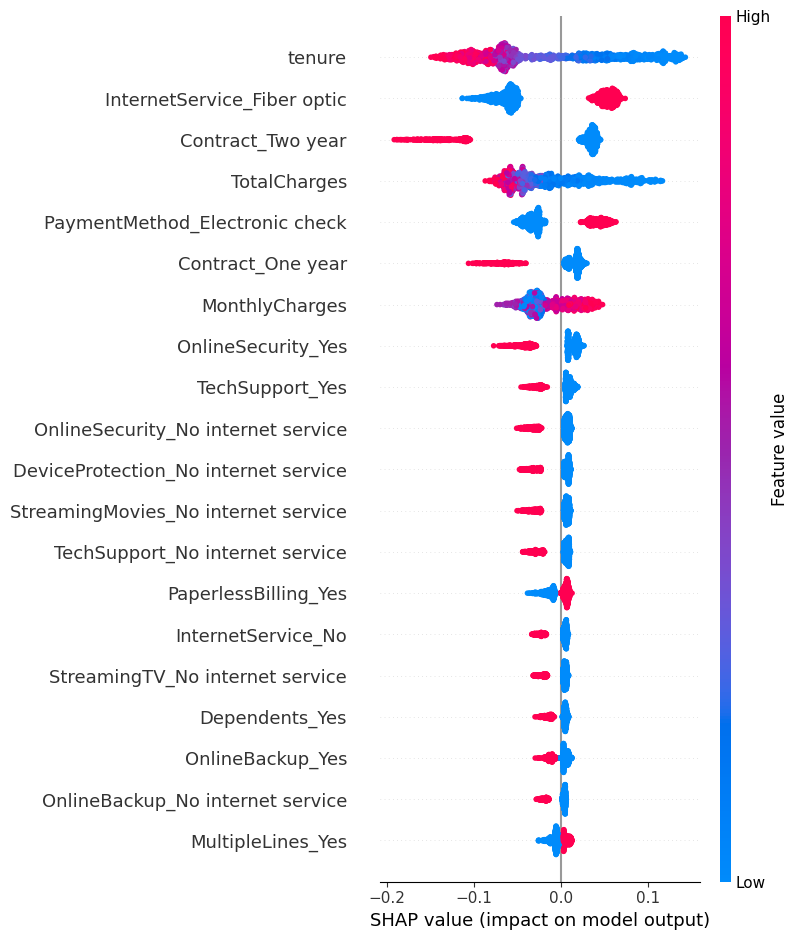

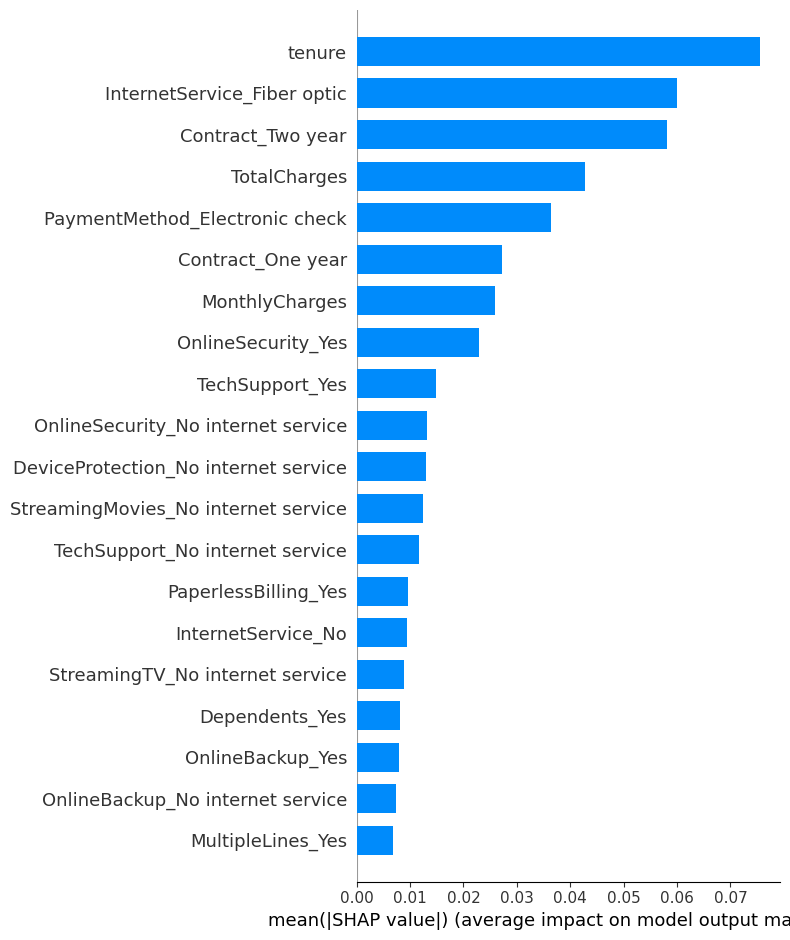

In [14]:
import shap
explainer = shap.TreeExplainer(best_rf)
sv = explainer.shap_values(X_test)
if isinstance(sv, list):        # older shap versions
    sv = sv[1]
elif sv.ndim == 3:              # newer shap versions
    sv = sv[:, :, 1]

shap.summary_plot(sv, X_test, show=True)
shap.summary_plot(sv, X_test, plot_type="bar", show=True)

In [15]:
import joblib, json, sklearn
THRESHOLD = 0.45

joblib.dump(best_rf, "churn_model.pkl")
joblib.dump(list(X.columns), "columns.pkl")
json.dump({"threshold": THRESHOLD}, open("config.json", "w"))
df.to_csv("clean_churn.csv", index=False)
results.to_csv("model_comparison.csv")   # for the dashboard/report
print("scikit-learn version:", sklearn.__version__)

from google.colab import files
for f in ["churn_model.pkl", "columns.pkl", "config.json", "clean_churn.csv", "model_comparison.csv"]:
    files.download(f)

scikit-learn version: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

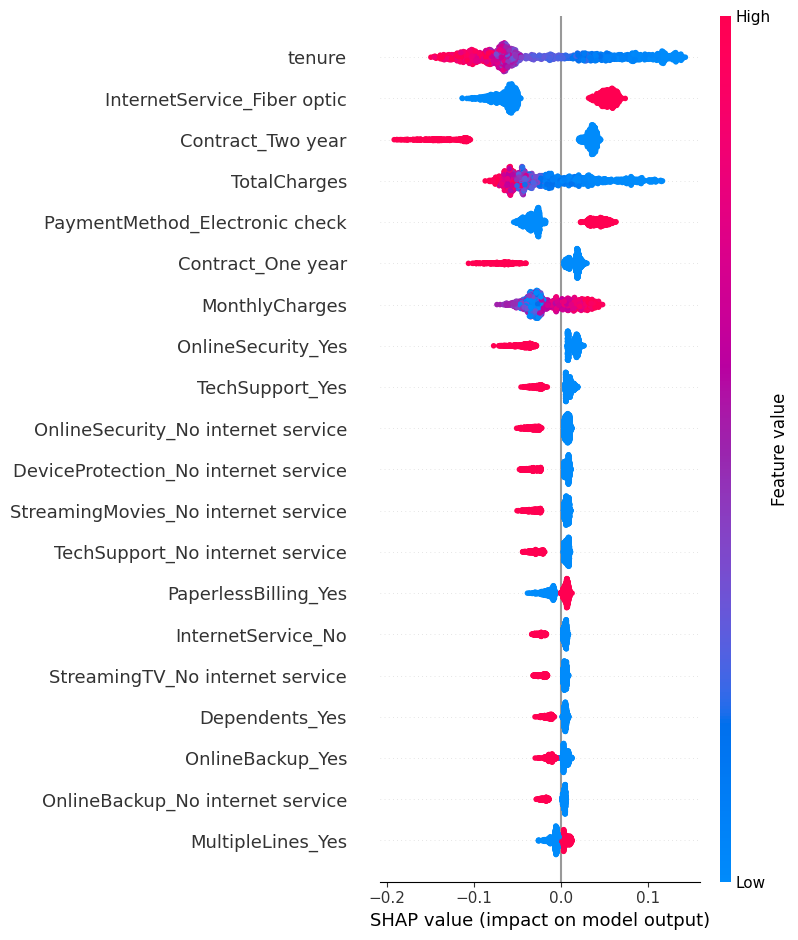

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
shap.summary_plot(sv, X_test, show=False)
plt.savefig("shap_summary.png", bbox_inches="tight", dpi=150)
plt.show()
files.download("shap_summary.png")